In [7]:
from sklearn.datasets import load_breast_cancer
from src.gaussian_mixture import GaussianMixtureMAR
from src.ampute_mar import AmputeMAR
from sklearn.model_selection import train_test_split

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score

import torch
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

Error importing in API mode: ImportError("dlopen(/Users/huimin/Documents/UNIGE PhD/research/nonparametric/.venv/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so, 0x0002): Library not loaded: /Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib\n  Referenced from: <1984CB9B-890E-3855-A246-270AC6AC4C62> /Users/huimin/Documents/UNIGE PhD/research/nonparametric/.venv/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so\n  Reason: tried: '/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file), '/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file)")
Trying to import in ABI mode.


In [2]:
# import os
# from pathlib import Path
# R_HOME = Path(r"C:\Users\hu\AppData\Local\Programs\R\R-4.5.3")
# assert (R_HOME / "bin" / "R.exe").exists(), "R.exe not found"
# assert (R_HOME / "bin" / "x64" / "R.dll").exists(), "R.dll not found"
# os.environ["R_HOME"] = str(R_HOME)
# os.environ["PATH"] = (
#     str(R_HOME / "bin" / "x64")
#     + os.pathsep
#     + str(R_HOME / "bin")
#     + os.pathsep
#     + os.environ["PATH"]
# )
# from src.ampute_mar import AmputeMAR

In [10]:
class Clustering(GaussianMixtureMAR):

    def __init__(self,
                 X,
                 M,
                 n_clusters=2,
                 k_range=None,
                 criterion="bic", 
                 cov_type='uni_diag', 
                 max_iter=100, 
                 tol=0.000001, 
                 eps=0.000001, 
                 reg_covar=0.000001, 
                 n_init=20, 
                 _k_tol=1, 
                 device="cpu", 
                 verbose=False):
        super().__init__(k_range, criterion, cov_type, max_iter, tol, eps, reg_covar, n_init, _k_tol, device, verbose)
        self.n_clusters = n_clusters
        self.model = self._fit(X, M)

    

    def _top_k_components(self, X, M=None, k=1):
        """
        Find which cluster each observation is mostly likely from
        """
        if M is None:
            M = torch.ones_like(X, device=X.device)
        _, indices = torch.topk(self.log_prob_N_K_D(X, M).sum(dim=2), dim=1, k=k)
        return indices

    def _fit(self, X, M):
        self.fit(X, M)
        return self.best_model

    def _cluster_centers(self):
        """
        Cluster Gaussian centers using train data
        """
        mu_np = self.model.mu.detach().cpu().numpy()
        kmeans = KMeans(n_clusters=self.n_clusters, n_init=20, random_state=123)
        return kmeans.fit_predict(mu_np)

    def cluster_through_centers(self, X, M):
        idx = self._top_k_components(X, M, k=1)
        self.center_labels = self._cluster_centers()
        return [self.center_labels[idx[i]].item() for i in range(len(idx))]

    def cluster_by_topk(self, X, M, k=3):
        idx = self._top_k_components(X, M, k)
        return idx

    def cluster_by_logprob(self, X, M):
        return self.log_prob_x_m(X, M)


# Simulation

In [67]:
# Simulate data
n = 5000
d = 30
norm1 = torch.distributions.MultivariateNormal(loc=torch.tensor([0.0, 0.0]), covariance_matrix=torch.tensor([[1.0,0.5], [0.5,1.0]]))
Y1 = norm1.sample((n,))
norm2 = torch.distributions.MultivariateNormal(loc=torch.tensor([5.0, 5.0]), covariance_matrix=torch.tensor([[1.0,0.5], [0.5,1.0]]))
Y2 = norm2.sample((int(n/2),))

U = torch.distributions.Uniform(0,1).sample((2,30))

In [68]:
X = Y1 @ U
idx = torch.randperm(n)[:int(n/2)]
X[idx] = Y2 @ U
X += torch.randn_like(X)

In [69]:
am = AmputeMAR()
M = am.ampute(X)[1]

In [70]:
true_labels = torch.ones(n)
true_labels[idx] = 2

Default of GMMMAR gives shared covariances of each center.

In [71]:
cl = Clustering(X, M, k_range=(0,20))
topk_ind = cl.cluster_by_logprob(X, M)

kmeans = KMeans(n_clusters=2, n_init=20, random_state=123)
labels_topk = kmeans.fit_predict(topk_ind)

labels_centers = cl.cluster_through_centers(X, M)

pca = PCA(n_components=2)
pcs = pca.fit_transform(X)

In [72]:
resp_sim = cl.get_resp(X, M)
combires_sim = entropy_combi(resp_sim, n_clusters=2)

In [73]:
print(cl.log_prob_x(X).sum())

tensor(-228203.5781)


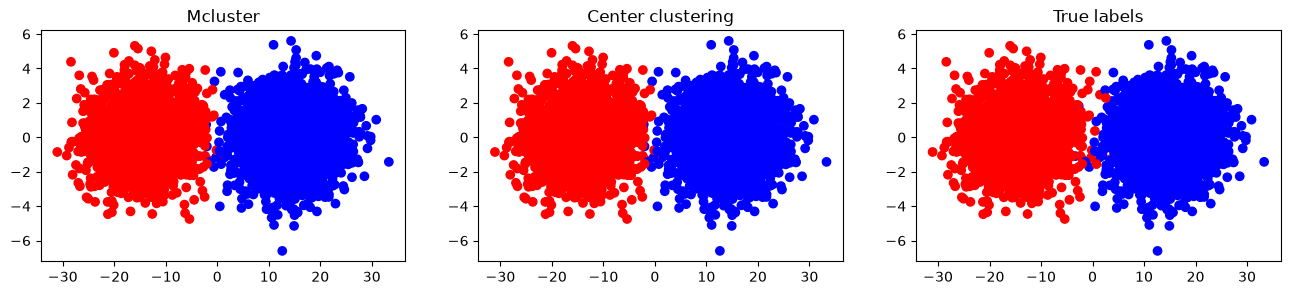

In [79]:
_, axes = plt.subplots(1,3, figsize=(16,3))
axes[0].scatter(pcs[:,0], pcs[:,1], c=np.where(combires_sim.labels, 'red', 'blue'))
axes[0].set_title('Mcluster')

axes[1].scatter(pcs[:,0], pcs[:,1], c=np.where(labels_centers, 'red', 'blue'))
axes[1].set_title('Center clustering')

axes[2].scatter(pcs[:,0], pcs[:,1], c=np.where(true_labels==1, 'red', 'blue'))
axes[2].set_title('True labels')

plt.show()

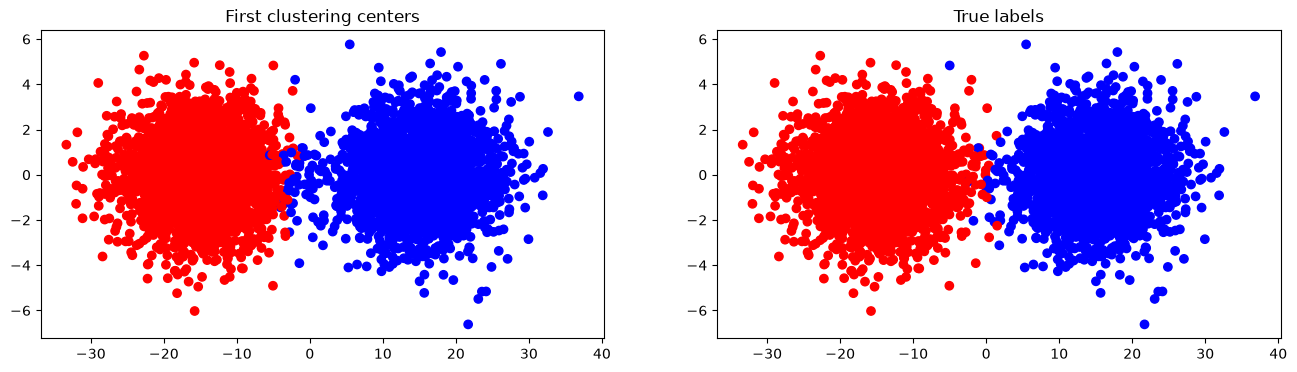

In [12]:
_, axes = plt.subplots(1,2, figsize=(16,4))
axes[0].scatter(pcs[:,0], pcs[:,1], c=np.where(labels_centers, 'red', 'blue'))
axes[0].set_title('First clustering centers')

# axes[1].scatter(pcs[:,0], pcs[:,1], c=np.where(labels_topk, 'red', 'blue'))
# axes[1].set_title('By logprob (N, K)')

axes[1].scatter(pcs[:,0], pcs[:,1], c=np.where(true_labels==1, 'red', 'blue'))
axes[1].set_title('True labels')

plt.show()

/var/folders/mv/wxrc6hsj1f5_jnvh03d4d14c0000gn/T/ipykernel_89213/2543044245.py:8: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(


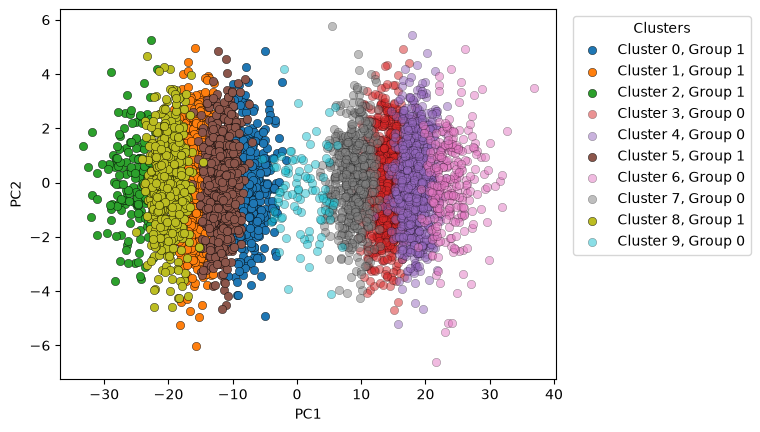

In [13]:
labels = cl.which_cluster(X, M)

cmap = plt.get_cmap("tab10", len(np.unique(labels)))

for k in np.unique(labels):
    mask = labels == k
    a = int(k in np.where(cl.center_labels==1)[0])
    plt.scatter(
        pcs[mask, 0],
        pcs[mask, 1],
        label=f"Cluster {k}, Group {a}",
        alpha= (a + 1) / 2,
        c=cmap(k),
        edgecolors="black",
        linewidths=0.3
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Clusters", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

In [14]:
cl = Clustering(X, M, k_range=(0,20))
topk_ind = cl.cluster_by_logprob(X, M)

kmeans = KMeans(n_clusters=2, n_init=20, random_state=123)
labels_topk = kmeans.fit_predict(topk_ind)


labels_centers = cl.cluster_through_centers(X, M)

pca = PCA(n_components=2)
pcs = pca.fit_transform(X)

In [15]:
print(cl.log_prob_x(X).sum())

tensor(-230921.)


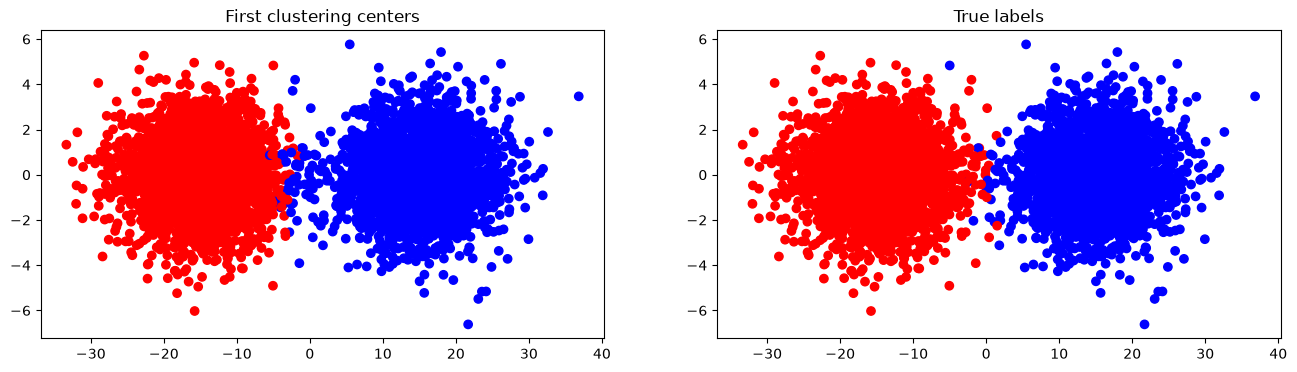

In [16]:
_, axes = plt.subplots(1,2, figsize=(16,4))

axes[0].scatter(pcs[:,0], pcs[:,1], c=np.where(labels_centers, 'red', 'blue'))
axes[0].set_title('First clustering centers')

# axes[1].scatter(pcs[:,0], pcs[:,1], c=np.where(labels_topk, 'red', 'blue'))
# axes[1].set_title('By logprob (N, K)')

axes[1].scatter(pcs[:,0], pcs[:,1], c=np.where(true_labels==1, 'red', 'blue'))
axes[1].set_title('True labels')

plt.show()

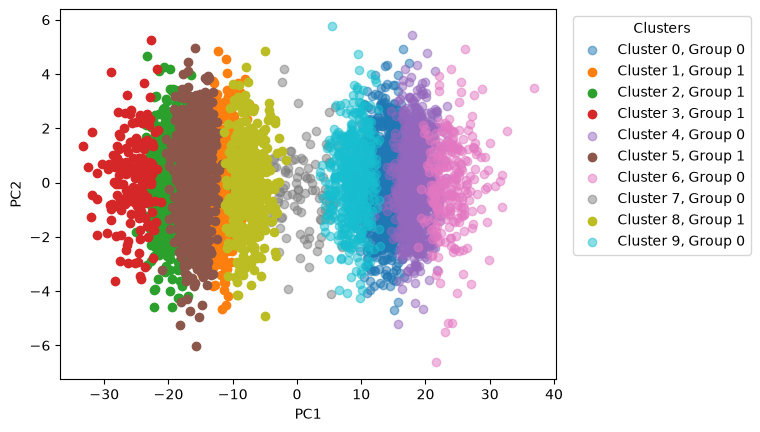

In [17]:
labels = cl.which_cluster(X, M)

for k in np.unique(labels):
    mask = labels == k
    a = int(k in np.where(cl.center_labels==1)[0])
    plt.scatter(
        pcs[mask, 0],
        pcs[mask, 1],
        label=f"Cluster {k}, Group {a}",
        alpha= (a + 1) / 2
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Clusters", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

# Breast Cancer Data

In [60]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X.to_numpy())
pca = PCA(n_components=2)
pcs = pca.fit_transform(X_scaled)

am = AmputeMAR()
M = am.ampute(torch.tensor(X.to_numpy()))[1]


# Xtrain, Xtest, Mtrain, Mtest, ytrain, ytest = train_test_split(
#     X, M, y, test_size=0.25, stratify=y, random_state=42)

# Mtrain = Mtrain.int()
# Mtest = Mtest.int()

In [62]:
Xfit = torch.tensor(X_scaled)
cl = Clustering(Xfit, M, k_range=(10,25))
resp = cl.get_resp(Xfit, M)

In [27]:
"""Hierarchical merging of Gaussian mixture components via the entropy
criterion of Baudry et al. (2010), "Combining Mixture Components for
Clustering", J. Comput. Graph. Stat. 19(2):332-353."""

from dataclasses import dataclass
import numpy as np


def _xlogx(x):
    """Elementwise x * log(x), with the convention 0 * log(0) = 0."""
    x = np.asarray(x, dtype=float)
    out = np.zeros_like(x)
    positive = x > 0
    out[positive] = x[positive] * np.log(x[positive])
    return out


def soft_entropy(tau):
    """Entropy of a soft clustering: -sum_i sum_k tau_ik * log(tau_ik)."""
    return -_xlogx(tau).sum()


@dataclass
class CombiResult:
    tau: np.ndarray           # (n_samples, n_clusters) merged posteriors
    labels: np.ndarray        # (n_samples,) hard cluster assignment
    merge_matrix: np.ndarray  # (n_clusters, K_initial); tau_merged = tau @ merge_matrix.T
    groups: list              # groups[j] = original component indices in cluster j
    merges: list              # (n_clusters_after, original components in 1st, in 2nd)
    entropies: dict           # {number of clusters: entropy}, useful for an entropy plot


def entropy_combi(tau, n_clusters, labels=None):
    """Merge mixture components down to `n_clusters` clusters.

    Parameters
    ----------
    tau : (n_samples, K) array
        Posterior membership probabilities from the fitted mixture
        (e.g. GaussianMixture.predict_proba). Rows must sum to 1.
    n_clusters : int
        Target number of clusters, 1 <= n_clusters <= K.
    labels : (n_samples,) int array, optional
        Hard labels in 0..K-1 from the original mixture. If given, they are
        remapped through the merges. If omitted, labels are the MAP
        assignment under the merged posteriors, as defined in the paper.
    """
    tau = np.asarray(tau, dtype=float)
    n_samples, K = tau.shape
    if not np.allclose(tau.sum(axis=1), 1.0, atol=1e-6):
        raise ValueError("Rows of tau must sum to 1.")
    if not 1 <= n_clusters <= K:
        raise ValueError(f"n_clusters must be between 1 and {K}.")

    current = tau.copy()                    # working posterior matrix
    groups = [[k] for k in range(K)]        # original components per current cluster
    merges = []
    entropies = {K: soft_entropy(current)}

    while current.shape[1] > n_clusters:
        n_cur = current.shape[1]
        # sum_i tau_ik * log(tau_ik) for each current column
        col_terms = _xlogx(current).sum(axis=0)

        # Merging columns a and b replaces them by their sum. The entropy
        # decrease is (a+b)log(a+b) - a log a - b log b, summed over samples.
        best_pair, best_decrease = None, -np.inf
        for a in range(n_cur - 1):
            for b in range(a + 1, n_cur):
                merged_term = _xlogx(current[:, a] + current[:, b]).sum()
                decrease = merged_term - col_terms[a] - col_terms[b]
                if decrease > best_decrease:
                    best_pair, best_decrease = (a, b), decrease

        a, b = best_pair
        merges.append((n_cur - 1, list(groups[a]), list(groups[b])))

        current[:, a] += current[:, b]      # cluster a absorbs cluster b
        current = np.delete(current, b, axis=1)
        groups[a] = groups[a] + groups[b]
        del groups[b]
        entropies[n_cur - 1] = soft_entropy(current)

    # Combining matrix: row j has ones for the original components in cluster j.
    merge_matrix = np.zeros((len(groups), K))
    comp_to_cluster = np.zeros(K, dtype=int)
    for j, members in enumerate(groups):
        merge_matrix[j, members] = 1.0
        comp_to_cluster[members] = j

    if labels is None:
        hard_labels = current.argmax(axis=1)
    else:
        hard_labels = comp_to_cluster[np.asarray(labels, dtype=int)]

    return CombiResult(current, hard_labels, merge_matrix, groups, merges, entropies)

In [63]:
combires = entropy_combi(resp, n_clusters=2)

In [64]:
kmeans = KMeans(n_clusters=2, n_init=20, random_state=123)
labels_centers = cl.cluster_through_centers(Xfit, M)

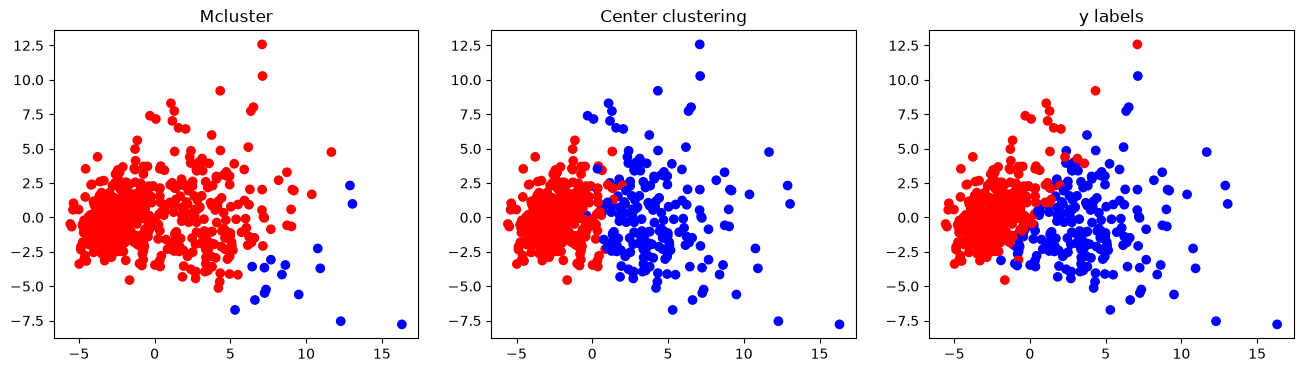

In [66]:
_, axes = plt.subplots(1,3, figsize=(16,4))

axes[0].scatter(pcs[:,0], pcs[:,1], c=np.where(combires.labels, 'red', 'blue'))
axes[0].set_title('Mcluster')

axes[1].scatter(pcs[:,0], pcs[:,1], c=np.where(labels_centers, 'red', 'blue'))
axes[1].set_title('Center clustering')

axes[2].scatter(pcs[:,0], pcs[:,1], c=np.where(y==1, 'red', 'blue'))
axes[2].set_title('y labels')

plt.show()

## R `mcluster`

In [ ]:
import rpy2.robjects as ro
from rpy2.robjects.packages import importr

from rpy2.robjects import ListVector, StrVector


def _to_r_matrix(X):
    return ro.r.matrix(
        ro.IntVector(X.T.flatten().tolist()),
        nrow=X.shape[0],
        ncol=X.shape[1],
    )


mcl = ListVector(
    {
        'z': _to_r_matrix(resp),
        'G': resp.shape[1]
    }
)

mcl.rclass = StrVector(["Mclust"])

mcluster = importr("mclust")

results = mcluster.clustCombi(mcl)

labels = np.array(results.rx2('classification')[2]) == 1

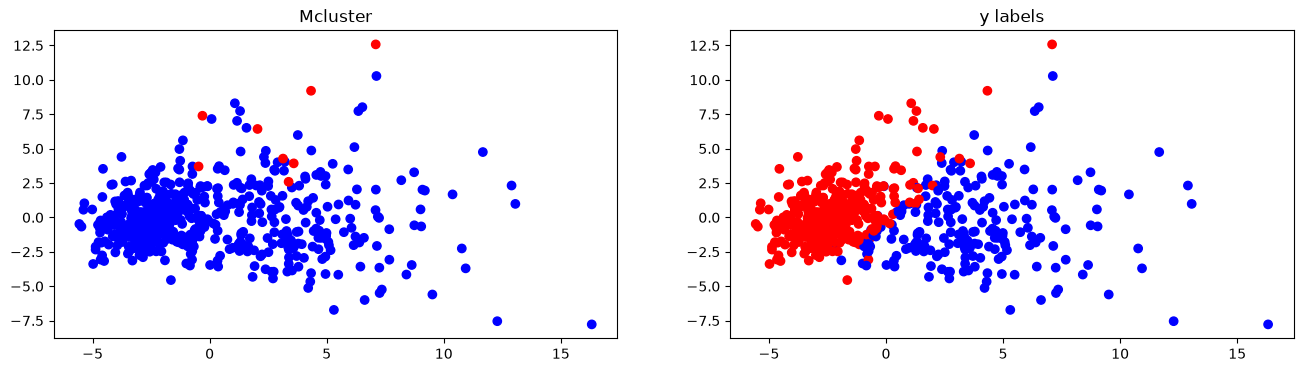

In [39]:
_, axes = plt.subplots(1,2, figsize=(16,4))

axes[0].scatter(pcs[:,0], pcs[:,1], c=np.where(combires.labels, 'red', 'blue'))
axes[0].set_title('Mcluster')

# axes[1].scatter(pcs[:,0], pcs[:,1], c=np.where(labels_topk, 'red', 'blue'))
# axes[1].set_title('By topk')

axes[1].scatter(pcs[:,0], pcs[:,1], c=np.where(y==1, 'red', 'blue'))
axes[1].set_title('y labels')

plt.show()

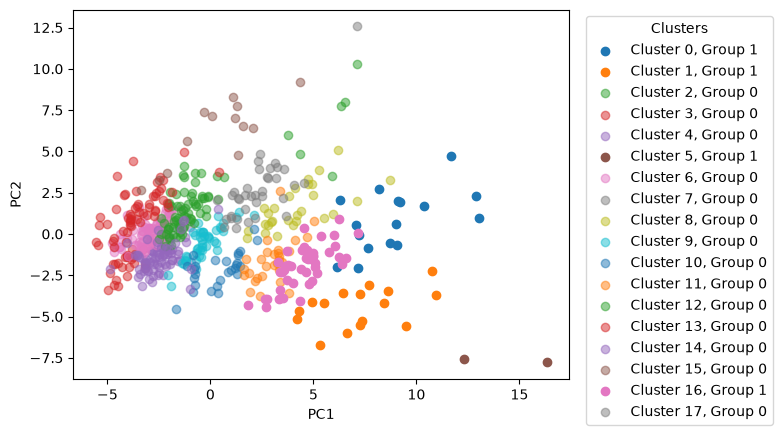

In [67]:
labels = cl.which_cluster(X, M)

for k in np.unique(labels):
    mask = labels == k
    a = int(k in np.where(cl.center_labels==1)[0])
    plt.scatter(
        pcs[mask, 0],
        pcs[mask, 1],
        label=f"Cluster {k}, Group {a}",
        alpha= (a + 1) / 2
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Clusters", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

In [26]:
# from drcme.post_gmm_merging import entropy_combi
# resp = resp.numpy()
# entropy_combi(resp, np.argmax(resp, axis=1), K_bic=cl.best_k)